In [ ]:

# Install libraries for the ML project
!python -m pip install numpy==2.2.0
!python -m pip install pandas==2.2.3
!python -m pip install scikit-learn==1.6.0
!python -m pip install matplotlib==3.9.3
!python -m pip install seaborn==0.13.2
!python -m pip install torch

In [3]:

import numpy as np                         # Numerical operations
import pandas as pd                        # Data manipulation
import torch                               # PyTorch models and tensors
import torch.nn as nn                      # Neural network layers
import torch.optim as optim                # Optimization algorithms
import matplotlib.pyplot as plt            # Plotting
import seaborn as sns                      # Statistical visualizations

from sklearn.model_selection import train_test_split  # Train/test split
from sklearn.preprocessing import StandardScaler      # Feature scaling
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc  # Evaluation


In [5]:
# Load the CSV dataset
data = pd.read_csv("league_of_legends_data_large.csv")  # Load the dataset

# Separate features (X) and target (y)
X = data.drop("win", axis=1)                 # All columns except 'win'
y = data["win"]                              # Target column: match outcome

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,                           # 20% test, 80% train
    random_state=42                          # Reproducible random split
)

# Standardize the features
scaler = StandardScaler()                    # Create a standardization object
X_train = scaler.fit_transform(X_train)      # Learn mean/std from train and scale it
X_test = scaler.transform(X_test)            # Scale test using training mean/std

# Convert features to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)  # Training features
X_test = torch.tensor(X_test, dtype=torch.float32)    # Testing features

# Convert target labels to PyTorch tensors
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32).view(-1, 1)  # Training labels
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32).view(-1, 1)    # Testing labels

In [6]:

# Import required libraries
import torch.nn as nn                      # Neural network layers and loss functions
import torch.optim as optim                # Optimization algorithms

# Define the logistic regression model
class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()                 # Initialize the parent class
        self.linear = nn.Linear(input_dim, 1)  # Map input features to one output

    def forward(self, x):
        return torch.sigmoid(self.linear(x))  # Convert output to probability (0 to 1)

# Initialize the model
input_dim = X_train.shape[1]               # Number of input features
model = LogisticRegressionModel(input_dim) # Create the model

# Define loss function and optimizer
criterion = nn.BCELoss()                   # Binary Cross-Entropy loss
optimizer = optim.SGD(model.parameters(), lr=0.01)  # SGD with learning rate 0.01


In [7]:

# Set the number of training epochs
epochs = 1000

# Train the model
for epoch in range(epochs):
    model.train()                           # Set model to training mode
    optimizer.zero_grad()                   # Reset gradients from previous iteration

    outputs = model(X_train)                # Predict outcomes using training data
    loss = criterion(outputs, y_train)      # Calculate prediction error

    loss.backward()                         # Compute gradients using backpropagation
    optimizer.step()                        # Update model weights using SGD

    if (epoch + 1) % 100 == 0:              # Print loss every 100 epochs
        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}")

# Evaluate the trained model
model.eval()                                # Set model to evaluation mode

with torch.no_grad():                       # Disable gradient calculations
    train_outputs = model(X_train)          # Predict probabilities on training data
    test_outputs = model(X_test)            # Predict probabilities on testing data

    train_preds = (train_outputs >= 0.5).float()  # Convert probabilities to 0 or 1
    test_preds = (test_outputs >= 0.5).float()    # Convert probabilities to 0 or 1

    train_accuracy = (train_preds == y_train).float().mean()  # Training accuracy
    test_accuracy = (test_preds == y_test).float().mean()     # Testing accuracy

# Display accuracy results
print(f"Training Accuracy: {train_accuracy.item() * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy.item() * 100:.2f}%")


Epoch [100/1000], Loss: 0.7122
Epoch [200/1000], Loss: 0.7018
Epoch [300/1000], Loss: 0.6953
Epoch [400/1000], Loss: 0.6914
Epoch [500/1000], Loss: 0.6890
Epoch [600/1000], Loss: 0.6875
Epoch [700/1000], Loss: 0.6866
Epoch [800/1000], Loss: 0.6861
Epoch [900/1000], Loss: 0.6858
Epoch [1000/1000], Loss: 0.6856
Training Accuracy: 53.62%
Testing Accuracy: 52.00%


In [8]:

# Initialize a fresh model for training with L2 regularization
model = LogisticRegressionModel(input_dim)       # Reset model weights
optimizer = optim.SGD(model.parameters(), lr=0.01, weight_decay=0.01)  # SGD with L2 regularization

# Set the number of training epochs
epochs = 1000

# Train the model with L2 regularization
for epoch in range(epochs):
    model.train()                                # Set model to training mode
    optimizer.zero_grad()                        # Reset previous gradients

    outputs = model(X_train)                     # Predict outcomes using training data
    loss = criterion(outputs, y_train)           # Calculate prediction error

    loss.backward()                              # Compute gradients using backpropagation
    optimizer.step()                             # Update weights with L2 regularization

    if (epoch + 1) % 100 == 0:                   # Print loss every 100 epochs
        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}")

# Evaluate the optimized model
model.eval()                                     # Set model to evaluation mode

with torch.no_grad():                            # Disable gradient calculations
    train_outputs = model(X_train)               # Predict training probabilities
    test_outputs = model(X_test)                 # Predict testing probabilities

    train_preds = (train_outputs >= 0.5).float()  # Convert training probabilities to 0 or 1
    test_preds = (test_outputs >= 0.5).float()    # Convert testing probabilities to 0 or 1

    train_accuracy = (train_preds == y_train).float().mean()  # Training accuracy
    test_accuracy = (test_preds == y_test).float().mean()     # Testing accuracy

# Display optimized model accuracy
print(f"Optimized Training Accuracy: {train_accuracy.item() * 100:.2f}%")
print(f"Optimized Testing Accuracy: {test_accuracy.item() * 100:.2f}%")


Epoch [100/1000], Loss: 0.7092
Epoch [200/1000], Loss: 0.6992
Epoch [300/1000], Loss: 0.6934
Epoch [400/1000], Loss: 0.6900
Epoch [500/1000], Loss: 0.6881
Epoch [600/1000], Loss: 0.6870
Epoch [700/1000], Loss: 0.6863
Epoch [800/1000], Loss: 0.6859
Epoch [900/1000], Loss: 0.6856
Epoch [1000/1000], Loss: 0.6855
Optimized Training Accuracy: 54.37%
Optimized Testing Accuracy: 51.50%


In [9]:

# Import required libraries
import matplotlib.pyplot as plt                       # Create plots
import seaborn as sns                                 # Visualize confusion matrix
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report  # Evaluation metrics

# Initialize a fresh model with L2 regularization
model = LogisticRegressionModel(input_dim)             # Create a new model
optimizer = optim.SGD(model.parameters(), lr=0.01, weight_decay=0.01)  # SGD with L2 regularization


In [10]:
# Retrain the model
epochs = 1000                                         # Number of training epochs

for epoch in range(epochs):
    model.train()                                     # Set model to training mode
    optimizer.zero_grad()                             # Reset previous gradients

    outputs = model(X_train)                          # Predict training outcomes
    loss = criterion(outputs, y_train)                # Calculate prediction error

    loss.backward()                                   # Compute gradients
    optimizer.step()                                  # Update model weights

    if (epoch + 1) % 100 == 0:                        # Print loss every 100 epochs
        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}")


Epoch [100/1000], Loss: 0.7186
Epoch [200/1000], Loss: 0.7048
Epoch [300/1000], Loss: 0.6967
Epoch [400/1000], Loss: 0.6919
Epoch [500/1000], Loss: 0.6891
Epoch [600/1000], Loss: 0.6875
Epoch [700/1000], Loss: 0.6866
Epoch [800/1000], Loss: 0.6861
Epoch [900/1000], Loss: 0.6857
Epoch [1000/1000], Loss: 0.6855


In [11]:
# Evaluate the model
model.eval()                                          # Set model to evaluation mode

with torch.no_grad():                                 # Disable gradient calculations
    train_probs = model(X_train).numpy().ravel()      # Training probabilities
    test_probs = model(X_test).numpy().ravel()        # Testing probabilities

# Convert probabilities to binary predictions
train_preds = (train_probs >= 0.5).astype(int)        # Training predictions: 0 or 1
test_preds = (test_probs >= 0.5).astype(int)          # Testing predictions: 0 or 1

# Convert actual labels to NumPy arrays
train_true = y_train.numpy().ravel().astype(int)      # Actual training labels
test_true = y_test.numpy().ravel().astype(int)        # Actual testing labels

# Calculate accuracy
train_accuracy = (train_preds == train_true).mean()   # Training accuracy
test_accuracy = (test_preds == test_true).mean()      # Testing accuracy

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")


Training Accuracy: 54.00%
Testing Accuracy: 49.50%


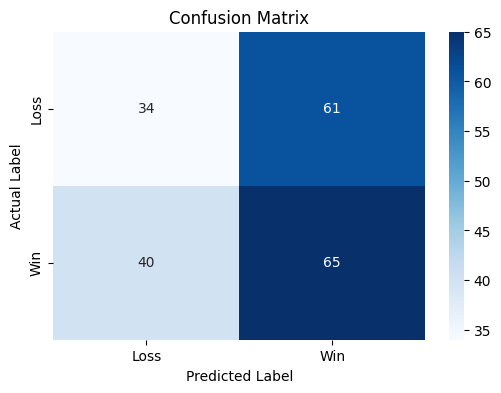

In [12]:
# Generate confusion matrix
cm = confusion_matrix(test_true, test_preds)          # Compare actual and predicted labels

plt.figure(figsize=(6, 4))                           # Set figure size
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Loss", "Win"],
            yticklabels=["Loss", "Win"])               # Display confusion matrix
plt.xlabel("Predicted Label")                         # X-axis label
plt.ylabel("Actual Label")                            # Y-axis label
plt.title("Confusion Matrix")                          # Plot title
plt.show()                                            # Display plot
